In [ ]:
import importlib.util
import subprocess
import sys

def ensure_package(package_name, import_name=None):
    import_name = import_name or package_name.split(">=")[0].split("==")[0].replace("-", "_")
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package_name])

ensure_package("timm>=1.0.0", "timm")
ensure_package("scikit-learn>=1.1.0", "sklearn")

import copy
import math
import os
import random
import subprocess
import tarfile
from pathlib import Path
import pickle
import csv

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from tqdm.auto import tqdm
import scipy.ndimage as ndimage

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, DataLoader, Dataset, Subset

import torchvision.transforms as transforms
from PIL import Image, ImageEnhance, ImageOps
import math
import cv2
from torchvision.transforms.functional import gaussian_blur
from scipy.ndimage import binary_dilation, binary_closing



import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
import random
import math
import csv

try:
    import albumentations as A
    HAS_ALBU = True
except ImportError:
    HAS_ALBU = False
    print("albumentations not available -> using simple resize/flip only")

In [ ]:
SEED = 7

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PIN_MEMORY = torch.cuda.is_available()
NUM_WORKERS = 0 if os.name != "nt" else 0

print(f"Using device: {DEVICE}")
if torch.cuda.is_available():
    print(torch.cuda.device_count())
    
from torch.utils.data import WeightedRandomSampler
from collections import Counter


Using device: cuda
1


In [ ]:
ROOT = "./Data"
CLASS_NAME= "class_01"
IMAGE_SIZE = 224
VAL_RATIO = 0

In [ ]:
# SAMELE utilities <3

def list_image_files(folder):
    folder = Path(folder)
    exts = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
    return sorted([p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in exts])

def pil_to_tensor(img):
    arr = np.asarray(img, dtype=np.float32)
    if arr.ndim == 2:
        arr = arr[..., None]
    arr = arr / 255.0
    return torch.from_numpy(arr).permute(2, 0, 1)

def tensor_to_numpy_image(x):
    if isinstance(x, torch.Tensor):
        x = x.detach().cpu().permute(1, 2, 0).numpy()
    return np.clip(x, 0.0, 1.0)

def tensor_to_numpy_mask(x):
    if isinstance(x, torch.Tensor):
        x = x.detach().cpu().squeeze().numpy()
    return x.astype(np.float32)

def _gaussian_kernel(window_size=11, sigma=1.5, channels=1, device="cpu", dtype=torch.float32):
    coords = torch.arange(window_size, device=device, dtype=dtype) - window_size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    kernel_2d = torch.outer(g, g)
    return kernel_2d.expand(channels, 1, window_size, window_size).contiguous()

def _filter2d(x, kernel):
    pad = kernel.shape[-1] // 2
    x = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    return F.conv2d(x, kernel, groups=x.shape[1])

def gaussian_blur(x, sigma=4.0):
    if sigma is None or sigma <= 0:
        return x
    kernel_size = int(max(3, 2 * round(4 * sigma) + 1))
    kernel_size += 1 - (kernel_size % 2)  # keep it odd
    kernel = _gaussian_kernel(
        window_size=kernel_size,
        sigma=float(sigma),
        channels=x.shape[1],
        device=x.device,
        dtype=x.dtype,
    )
    return _filter2d(x, kernel)

def normalize_map(amap):
    amap = np.asarray(amap, dtype=np.float32)
    if amap.max() <= amap.min():
        return np.zeros_like(amap)
    return (amap - amap.min()) / (amap.max() - amap.min() + 1e-8)

def heatmap_overlay(image, amap, alpha=0.45):
    image = tensor_to_numpy_image(image)
    heat = plt.cm.jet(normalize_map(amap))[..., :3]
    return np.clip((1.0 - alpha) * image + alpha * heat, 0.0, 1.0)

def show_detection_results(results, n=5, include_reconstruction=False, thresholds=None, title=None):
    if len(results) == 0:
        return
    chosen = [0, 23, 68, 89, 112]

    n_cols = 5 if include_reconstruction else 4
    fig, axes = plt.subplots(len(chosen), n_cols, figsize=(4 * n_cols, 3.7 * len(chosen)))
    if len(chosen) == 1:
        axes = np.expand_dims(axes, axis=0)

    if title is not None:
        fig.suptitle(title, fontsize=16, y=1.02)

    for row, idx in enumerate(chosen):
        r = results[idx]
        img = r["image"]
        amap = r["anomaly_map"]
        mask = r["mask"]

        col = 0
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"Input\nlabel={r['label']} score={r['score']:.4f}")
        axes[row, col].axis("off")
        col += 1

        if include_reconstruction:
            axes[row, col].imshow(r["reconstruction"])
            axes[row, col].set_title("Reconstruction")
            axes[row, col].axis("off")
            col += 1

        axes[row, col].imshow(heatmap_overlay(img, amap))
        axes[row, col].set_title("Overlay")
        axes[row, col].axis("off")
        col += 1

        im = axes[row, col].imshow(amap, cmap="jet")
        axes[row, col].set_title("Anomaly map")
        axes[row, col].axis("off")
        plt.colorbar(im, ax=axes[row, col], fraction=0.046, pad=0.04)
        col += 1

        if thresholds is None:
            axes[row, col].imshow(mask, cmap="gray")
            axes[row, col].set_title("GT mask")
            axes[row, col].axis("off")
        else:
            pred_mask = (amap >= thresholds["pixel_threshold"]).astype(np.float32)
            panel = np.concatenate([mask, pred_mask], axis=1)
            axes[row, col].imshow(panel, cmap="gray")
            axes[row, col].set_title("GT mask | Pred mask")
            axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()

def safe_metric(metric_fn, y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    if np.unique(y_true).size < 2:
        return np.nan
    return float(metric_fn(y_true, scores))

def youden_threshold(y_true, y_score):
    """
    Return the threshold that maximizes the Youden statistic:
        J = sensitivity + specificity - 1 = TPR - FPR

    Returns np.nan when the threshold cannot be computed
    (for example, if only one class is present).
    """
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    # ROC/Youden is undefined if only one class is present
    if y_true.size == 0 or np.unique(y_true).size < 2:
        return np.nan

    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    return float(thresholds[best_idx])

def summarize_metrics(results):
    image_labels = np.array([r["label"] for r in results], dtype=np.int64)
    image_scores = np.array([r["score"] for r in results], dtype=np.float32)

    pixel_masks = np.concatenate([r["mask"].reshape(-1) for r in results]).astype(np.uint8)
    pixel_scores = np.concatenate([r["anomaly_map"].reshape(-1) for r in results]).astype(np.float32)

    metrics = {
        "image_auroc": safe_metric(roc_auc_score, image_labels, image_scores),
        "image_ap": safe_metric(average_precision_score, image_labels, image_scores),
        "image_threshold": youden_threshold(image_labels, image_scores),
        "pixel_auroc": safe_metric(roc_auc_score, pixel_masks, pixel_scores),
        "pixel_ap": safe_metric(average_precision_score, pixel_masks, pixel_scores),
        "pixel_threshold": youden_threshold(pixel_masks, pixel_scores),
    }
    return metrics
import re
from collections import defaultdict

_VIEW_RE = re.compile(r"(?P<base>.+)_view(?P<view>\d+)$")

def _split_base_view(p: Path):
    stem = p.stem
    m = _VIEW_RE.match(stem)
    if m:
        return m.group("base"), int(m.group("view"))
    return stem, None

class SingleClassDataset(Dataset):
    def __init__(self, root, class_name, split="train", image_size=224,
                 multi_view=True, require_all_views=True,
                 include_train_anomalies=False, only_anomalies=False):
        self.root = Path(root)
        self.class_name = class_name
        self.split = split
        self.image_size = image_size
        self.multi_view = multi_view
        self.require_all_views = require_all_views
        self.include_train_anomalies = include_train_anomalies
        self.only_anomalies = only_anomalies
        self.class_root = self.root / class_name
        self.samples = []

        if split not in {"train", "test"}:
            raise ValueError("split must be 'train' or 'test'")

        gt_root = self.class_root / "ground_truth_train"

        if split == "train":
            good_dir = self.class_root / "train" / "good"
            anomaly_dirs = []
            if include_train_anomalies:
                train_dir = self.class_root / "train"
                anomaly_dirs = sorted([
                    d for d in train_dir.iterdir()
                    if d.is_dir() and d.name.startswith("anomaly_")
                ])
            if only_anomalies and not include_train_anomalies:
                raise ValueError("only_anomalies=True requires include_train_anomalies=True")

            if not multi_view:
                if not only_anomalies:
                    for p in list_image_files(good_dir):
                        base, view = _split_base_view(p)
                        self.samples.append({
                            "image_path": p,
                            "mask_path": None,
                            "label": 0,
                            "defect_type": "good",
                            "view": view,
                            "base_id": base,
                        })
                if include_train_anomalies:
                    for anomaly_dir in anomaly_dirs:
                        for p in list_image_files(anomaly_dir):
                            base, view = _split_base_view(p)
                            mask_path = None
                            if gt_root.exists():
                                candidate = gt_root / anomaly_dir.name / f"{base}_view{view}.png"
                                if candidate.exists():
                                    mask_path = candidate
                            self.samples.append({
                                "image_path": p,
                                "mask_path": mask_path,
                                "label": 1,
                                "defect_type": anomaly_dir.name,
                                "view": view,
                                "base_id": base,
                            })
            else:
                if not only_anomalies:
                    groups = defaultdict(dict)
                    for p in list_image_files(good_dir):
                        base, view = _split_base_view(p)
                        groups[base][view] = p
                    for base, views_map in groups.items():
                        if self.require_all_views and len(views_map) != 5:
                            continue
                        view_paths = [views_map.get(i+1) for i in range(5)]
                        self.samples.append({
                            "base_id": base,
                            "view_paths": view_paths,
                            "mask_paths": [None]*5,
                            "label": 0,
                            "defect_type": "good",
                        })
                if include_train_anomalies:
                    anomaly_groups = defaultdict(dict)
                    anomaly_masks = defaultdict(dict)
                    anomaly_defect_type = {}
                    for anomaly_dir in anomaly_dirs:
                        for p in list_image_files(anomaly_dir):
                            base, view = _split_base_view(p)
                            anomaly_groups[base][view] = p
                            candidate = gt_root / anomaly_dir.name / f"{base}_view{view}.png"
                            if candidate.exists():
                                anomaly_masks[base][view] = candidate
                            anomaly_defect_type[base] = anomaly_dir.name
                    for base, views_map in anomaly_groups.items():
                        if self.require_all_views and len(views_map) != 5:
                            continue
                        view_paths = [views_map.get(i+1) for i in range(5)]
                        mask_paths = [anomaly_masks[base].get(i+1) for i in range(5)]
                        self.samples.append({
                            "base_id": base,
                            "view_paths": view_paths,
                            "mask_paths": mask_paths,
                            "label": 1,
                            "defect_type": anomaly_defect_type.get(base, "anomaly"),
                        })

        else:  # test
            test_root = self.class_root / "test"
            all_test_imgs = list_image_files(test_root)
            if not multi_view:
                for p in all_test_imgs:
                    base, view = _split_base_view(p)
                    mask_path = None
                    defect_type = "good"
                    # search all gt dirs for mask with same base+view
                    if gt_root.exists():
                        for d in gt_root.iterdir():
                            candidate = d / f"{base}_view{view}.png"
                            if candidate.exists():
                                mask_path = candidate
                                defect_type = d.name
                                break
                    label = 1 if mask_path is not None else 0
                    self.samples.append({
                        "image_path": p,
                        "mask_path": mask_path,
                        "label": label,
                        "defect_type": defect_type,
                        "view": view,
                        "base_id": base,
                    })
            else:
                groups = defaultdict(dict)
                masks_by_base = defaultdict(dict)
                for p in all_test_imgs:
                    base, view = _split_base_view(p)
                    groups[base][view] = p
                    # find mask
                    if gt_root.exists():
                        for d in gt_root.iterdir():
                            candidate = d / f"{base}_view{view}.png"
                            if candidate.exists():
                                masks_by_base[base][view] = candidate
                                break
                for base, views_map in groups.items():
                    if self.require_all_views and len(views_map) != 5:
                        continue
                    view_paths = [views_map.get(i+1) for i in range(5)]
                    mask_paths = [masks_by_base[base].get(i+1) for i in range(5)]
                    label = 1 if any(x is not None for x in mask_paths) else 0
                    defect_type = None
                    if label:
                        # pick first defect dir that had a mask (coarse)
                        for d in gt_root.iterdir():
                            if any((d / f"{base}_view{i+1}.png").exists() for i in range(5)):
                                defect_type = d.name
                                break
                    self.samples.append({
                        "base_id": base,
                        "view_paths": view_paths,
                        "mask_paths": mask_paths,
                        "label": label,
                        "defect_type": defect_type or "good",
                    })

        if len(self.samples) == 0:
            raise RuntimeError(f"No samples found for class='{class_name}', split='{split}' under {self.class_root}")

    def __len__(self):
        return len(self.samples)

    def _load_image(self, p):
        img = Image.open(p).convert("RGB")
        img = img.resize((self.image_size, self.image_size), resample=Image.BILINEAR)
        return pil_to_tensor(img)

    def __getitem__(self, idx):
        r = self.samples[idx]
        if not self.multi_view:
            image = self._load_image(r["image_path"])
            if r["mask_path"] is None:
                mask = torch.zeros((1, self.image_size, self.image_size), dtype=torch.float32)
            else:
                mask = Image.open(r["mask_path"]).convert("L")
                mask = mask.resize((self.image_size, self.image_size), resample=Image.NEAREST)
                mask = (pil_to_tensor(mask) > 0.5).float()
            return {
                "image": image,
                "mask": mask,
                "label": torch.tensor(r["label"], dtype=torch.long),
                "defect_type": r["defect_type"],
                "path": str(r["image_path"]),
                "view": r.get("view"),
                "base_id": r.get("base_id"),
            }
        else:
            imgs = []
            masks = []
            for p in r["view_paths"]:
                imgs.append(self._load_image(p) if p is not None else torch.zeros((3, self.image_size, self.image_size)))
            for mp in r["mask_paths"]:
                if mp is None:
                    masks.append(torch.zeros((1, self.image_size, self.image_size), dtype=torch.float32))
                else:
                    mask = Image.open(mp).convert("L")
                    mask = mask.resize((self.image_size, self.image_size), resample=Image.NEAREST)
                    masks.append((pil_to_tensor(mask) > 0.5).float())
            images_stack = torch.stack(imgs, dim=0)        # shape (5, C, H, W)
            masks_stack = torch.stack(masks, dim=0)        # shape (5, 1, H, W)
            return {
                "images": images_stack,
                "masks": masks_stack,
                "label": torch.tensor(r["label"], dtype=torch.long),
                "defect_type": r["defect_type"],
                "base_id": r["base_id"],
            }


def split_train_val(dataset, val_ratio=0.15, seed=SEED):
    n = len(dataset)
    indices = np.arange(n)
    rng = np.random.default_rng(seed)
    rng.shuffle(indices)
    n_val = max(1, int(round(n * val_ratio)))
    val_idx = indices[:n_val]
    train_idx = indices[n_val:]
    return Subset(dataset, train_idx.tolist()), Subset(dataset, val_idx.tolist())

train_full_dataset = SingleClassDataset(ROOT, CLASS_NAME, split="train", image_size=IMAGE_SIZE)
val_anomaly_dataset = SingleClassDataset(
    ROOT,
    CLASS_NAME,
    split="train",
    image_size=IMAGE_SIZE,
    include_train_anomalies=True,
    only_anomalies=True,
)
train_dataset, val_normal_dataset = split_train_val(train_full_dataset, val_ratio=VAL_RATIO, seed=SEED)
val_dataset = ConcatDataset([val_normal_dataset, val_anomaly_dataset])
test_dataset = SingleClassDataset(ROOT, CLASS_NAME, split="test", image_size=IMAGE_SIZE)

print(f"Train normals (full): {len(train_full_dataset)}")
print(f"Train normals (used for fitting): {len(train_dataset)}")
print(f"Validation normals: {len(val_normal_dataset)}")
print(f"Validation anomalies: {len(val_anomaly_dataset)}")
print(f"Validation total: {len(val_dataset)}")
#print(f"Test images: {len(test_dataset)}")

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)



## DINOv2 Feature Extractor

This cell defines a feature extractor built on top of a frozen **DINOv2** Vision Transformer. Instead of using only the final layer, it pulls features from **multiple intermediate layers** of the transformer and combines them into a single dense feature map per image.

### What it does, step by step

1. **Load the backbone.** A pretrained DINOv2 model (here `dinov2_vitl14_reg`) is loaded from torch hub, set to `eval()` mode, and all its parameters are frozen — we only use it as a fixed feature extractor.

2. **Input normalization.** The input image is normalized using the standard ImageNet mean/std, which is what DINOv2 expects.

3. **Multi-layer feature extraction.** Using `get_intermediate_layers`, features are pulled from the selected transformer blocks (`layers=[11, 15, 19, 23]`). Earlier layers capture more low-level / textural information, while deeper layers capture more semantic information — combining them gives a richer representation.

4. **Reshape patches into a spatial grid.** DINOv2 returns a sequence of patch tokens of shape `(B, N, C)`. These are reshaped back into a 2D grid `(B, C, H/14, W/14)` so we get a feature map aligned with image space.

5. **Local pooling** A 3×3 average pooling with stride 1 smooths the features over neighboring patches, making them slightly more spatially coherent without changing resolution.

6. **Concatenation.** The feature maps from all selected layers are concatenated along the channel dimension, producing a feature map of dimension `embed_dim * num_layers`.

7. **Random projection (optional).** If `out_dim` is set, the concatenated features are projected down to a smaller dimension (here `2048`) using a fixed random Gaussian matrix (seeded for reproducibility). This keeps the representation compact while preserving most of the structure.

8. **Output format.** The final tensor is permuted to `(B, H, W, C)`, ready to be used as a dense per-patch feature map.

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

class DINOv2FeatureExtractorV2(nn.Module):
    
    def __init__(self,
                 device=DEVICE,
                 layers=(5, 8, 11),
                 out_dim=None,
                 local_pool=True,
                 backbone='dinov2_vitb14',
                 seed=SEED):
        super().__init__()
        self.device = device
        self.layers = list(layers)
        self.local_pool = local_pool


        self.model = torch.hub.load('facebookresearch/dinov2', backbone, pretrained=True)
        self.model.eval().to(device)
        for p in self.model.parameters():
            p.requires_grad = False


        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std",  torch.tensor(IMAGENET_STD,  device=device).view(1, 3, 1, 1), persistent=False)

       
        self.patch_h = IMAGE_SIZE // 14
        self.patch_w = IMAGE_SIZE // 14

       
        self.dim_per_layer = self.model.embed_dim
        self.concat_dim = self.dim_per_layer * len(self.layers)

       
        if out_dim is None:
            self.out_dim = self.concat_dim
            self.register_buffer("proj", torch.empty(0), persistent=False)
            self._use_proj = False
        else:
            self.out_dim = out_dim
            g = torch.Generator().manual_seed(seed)
            proj = torch.randn(self.concat_dim, out_dim, generator=g) / (self.concat_dim ** 0.5)
            self.register_buffer("proj", proj.to(device), persistent=True)
            self._use_proj = True

        self._pool = nn.AvgPool2d(kernel_size=3, stride=1, padding=1) if local_pool else nn.Identity()

        self.feature_dim = self.out_dim

        print(f"[DINOv2 v2] backbone={backbone} layers={self.layers} "
              f"local_pool={local_pool} concat_dim={self.concat_dim} out_dim={self.out_dim}")

    @torch.no_grad()
    def forward(self, x):
        x = (x - self.mean) / self.std

        layer_feats = self.model.get_intermediate_layers(
            x,
            n=self.layers,
            reshape=False,
            return_class_token=False,
            norm=True,
        )  

        pooled = []
        for feat in layer_feats:
            B, N, C = feat.shape
            f = feat.transpose(1, 2).reshape(B, C, self.patch_h, self.patch_w)
            f = self._pool(f)  
            pooled.append(f)

        
        combined = torch.cat(pooled, dim=1)
        combined = combined.permute(0, 2, 3, 1).contiguous()

       
        if self._use_proj:
            combined = combined @ self.proj

        return combined  


dino_extractor = DINOv2FeatureExtractorV2(
    layers=[11, 15, 19, 23],
    out_dim=2048,                    
    local_pool=True,
    backbone='dinov2_vitl14_reg',
)


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitl14/dinov2_vitl14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitl14_reg4_pretrain.pth


100%|██████████| 1.13G/1.13G [00:06<00:00, 194MB/s]


[DINOv2 v2] backbone=dinov2_vitl14_reg layers=[11, 15, 19, 23] local_pool=True concat_dim=4096 out_dim=2048


## MVAS: Multi-View Attention Sharing

Enriches each view's features by letting it attend to features from **other views of the same scene**, producing more consistent representations.

### Components
- **`linear_q`**, **`linear_kv`**: query and key/value projections, seeded init.
- **`_patch` / `_unpatch`**: split a feature map into an `a × a` grid of windows and reassemble — keeps attention local and cheap.

### Forward pass — three modes

**1. Inference with memory bank.** Queries come from the views, keys/values from the memory bank. One global attention pass aligns features to a fixed reference pool.

**2. Training (cross-view attention).** For each view `j`:
- Queries from view `j`, keys/values from the other views, all split into matching windows.
- **Top-k view selection**: per window, score sibling views by mean Q·K similarity and keep only the top `k`. Sparse over views, dense within.
- Run attention and unpatch back to `(H, W, C)`.

**3. Eval without memory bank.** Pass-through.

### Instantiation
Built with `dim` matching the DINOv2 output, a `4×4` window grid, and `k=5` views selected per window.

In [ ]:
class MVAS(nn.Module):
    def __init__(self, dim=768, a=4, k=5, seed=42):
        super().__init__()
        self.dim = dim
        self.a = a
        self.k = k

        gen = torch.Generator().manual_seed(seed)

        self.linear_q = nn.Linear(dim, dim, bias=False)
        self.linear_q.weight.data = torch.randn(dim, dim, generator=gen) / (dim ** 0.5)

        self.linear_kv = nn.Linear(dim, dim * 2, bias=False)
        self.linear_kv.weight.data = torch.randn(dim * 2, dim, generator=gen) / (dim ** 0.5)

    def _patch(self, x, a):
        H, W, C = x.shape
        ph, pw = H // a, W // a
        x = x.reshape(a, ph, a, pw, C).permute(0, 2, 1, 3, 4)
        return x.reshape(a * a, ph * pw, C), ph, pw

    def _unpatch(self, x, a, ph, pw, H, W):
        C = x.shape[-1]
        x = x.reshape(a, a, ph, pw, C).permute(0, 2, 1, 3, 4)
        return x.reshape(H, W, C)

    def forward(self, views, memory_bank=None):
        V_dim, H, W, C = views.shape
        a = self.a

        if memory_bank is not None:
            x_flat = views.reshape(-1, C)         # (V*H*W, C)
            Q = self.linear_q(x_flat)             # (V*H*W, C)

            KV = self.linear_kv(memory_bank)      # (M, 2*C)
            K, Va = KV.split(C, dim=-1)           # (M, C), (M, C)

            attn_out = F.scaled_dot_product_attention(
                Q.unsqueeze(0), K.unsqueeze(0), Va.unsqueeze(0)
            ).squeeze(0)                          # (V*H*W, C)

            return attn_out.reshape(V_dim, H, W, C)

        if self.training:
            enriched = []
            for j in range(V_dim):
                xj = views[j]
                q_patches, ph, pw = self._patch(xj, a)
                Q = self.linear_q(q_patches)

                other_indices = [i for i in range(V_dim) if i != j]
                others = views[other_indices]

                kv_list = []
                for ov in others:
                    ov_patches, _, _ = self._patch(ov, a)
                    kv_list.append(ov_patches)
                kv_stacked = torch.stack(kv_list, dim=1).reshape(
                    a * a, (V_dim - 1) * ph * pw, C
                )

                KV = self.linear_kv(kv_stacked)
                K, Va = KV.split(C, dim=-1)

                n_windows = a * a
                K_wins  = K.reshape(n_windows, V_dim - 1, ph * pw, C)
                Va_wins = Va.reshape(n_windows, V_dim - 1, ph * pw, C)

                q_mean = Q.mean(dim=1)
                k_mean = K_wins.mean(dim=2)
                scores = torch.einsum('nc,nvc->nv', q_mean, k_mean) / (C ** 0.5)

                topk = min(self.k, V_dim - 1)
                _, topk_idx = scores.topk(topk, dim=-1)

                idx_exp = topk_idx.unsqueeze(-1).unsqueeze(-1).expand(-1, -1, ph * pw, C)
                K_sel  = K_wins.gather(1, idx_exp).reshape(n_windows, topk * ph * pw, C)
                Va_sel = Va_wins.gather(1, idx_exp).reshape(n_windows, topk * ph * pw, C)

                attn_out = F.scaled_dot_product_attention(Q, K_sel, Va_sel)
                enriched_j = self._unpatch(attn_out, a, ph, pw, H, W)
    
                enriched.append(enriched_j)

            return torch.stack(enriched, dim=0)

        return views

mvas = MVAS(dim=dino_extractor.feature_dim, a=4, k=5, seed=SEED).to(DEVICE)

## MVAD Pipeline

End-to-end anomaly detection pipeline that combines **PatchCore-style nearest-neighbor search** with **MVAS reconstruction error** over multi-view inputs.

### Init
Stores the DINOv2 extractor, the MVAS module, coreset ratio, blur sigma, training config, and an Adam optimizer for MVAS. Two scale factors (`nn_scale`, `mvas_scale`) are calibrated later to make the two anomaly signals comparable.

### Helpers
- **`_nn_search`**: chunked L2 distance from each query patch to its nearest neighbor in the memory bank.
- **`_greedy_coreset`**: farthest-point sampling to pick a representative subset of patches.
- **`_dino_only`**: raw DINOv2 features for a 5-view group, no MVAS applied.

### `fit` — four phases

**Phase 1 — Train MVAS.** For each multi-view group, extract frozen DINOv2 features and train MVAS to reconstruct them (MSE loss). This teaches MVAS what "normal" cross-view consistency looks like.

**Phase 2 — Memory bank.** Collect L2-normalized DINOv2 patches from the whole training set, randomly subsample candidates, then run greedy coreset to keep a compact, diverse subset as the memory bank.

**Phase 3 — Calibration.** On a subset of groups, collect both signals (NN distances and MVAS cosine-distance reconstruction errors) and store their high percentiles as normalization scales.

### `predict`
For each view group:
1. Extract DINOv2 features.
2. **NN map**: nearest-neighbor distance to the memory bank per patch.
3. **Recon map**: cosine distance between features and their MVAS reconstruction (queried against the memory bank).
4. Upsample to image size, Gaussian-blur, and shift to zero min.
5. Per-image score = 99.5th percentile of the anomaly map.

Returns a list of dicts with image, anomaly map, mask, label, score, and metadata for each view.

In [ ]:
MVAS_A = 4
MVAS_K = 5
CORESET_RATIO = 0.2
ANOMALY_MAP_SIGMA = 1.5
IMAGE_SIZE = 224


_DEFAULT_NN_SCALE   = 1.0
_DEFAULT_MVAS_SCALE = 1.0


class MVADPipeline:
   
    def __init__(self, dino, mvas_module, coreset_ratio=0.01, sigma=4.0,
                 device="cuda", lr=1e-4, epochs=3,
                 recon_weight=0.5):
        self.dino = dino
        self.mvas = mvas_module
        self.coreset_ratio = coreset_ratio
        self.sigma = sigma
        self.device = device
        self.memory_bank = None
        self.torch_bank = None
        self.epochs = epochs
        self.recon_weight = recon_weight
        self.optimizer = torch.optim.Adam(self.mvas.parameters(), lr=lr)
        self.loss_fn = torch.nn.MSELoss()

        self.nn_scale   = _DEFAULT_NN_SCALE
        self.mvas_scale = _DEFAULT_MVAS_SCALE

    @torch.no_grad()
    def _nn_search(self, queries: np.ndarray, chunk_size: int = 2048) -> np.ndarray:
        q = torch.from_numpy(queries).to(self.device)
        min_dists = []
        for i in range(0, q.shape[0], chunk_size):
            q_chunk = q[i:i + chunk_size]
            dists = torch.cdist(q_chunk, self.torch_bank, p=2)
            min_dists.append(dists.min(dim=1).values.cpu().numpy())
        return np.concatenate(min_dists)

    def _greedy_coreset(self, points: np.ndarray, k: int, seed: int = 42) -> np.ndarray:
        n, d = points.shape
        if n <= k:
            return np.arange(n)
        rng = np.random.RandomState(seed)
        first_idx = rng.randint(0, n)
        selected = [first_idx]
        pts = torch.from_numpy(points).to(self.device)
        first = pts[first_idx].unsqueeze(0)
        min_dists = torch.cdist(pts, first, p=2).squeeze(1)
        for _ in tqdm(range(1, k), desc="Greedy coreset", leave=False):
            next_idx = int(min_dists.argmax().item())
            selected.append(next_idx)
            new_pt = pts[next_idx].unsqueeze(0)
            dists_to_new = torch.cdist(pts, new_pt, p=2).squeeze(1)
            min_dists = torch.minimum(min_dists, dists_to_new)
        return np.array(selected)

    @torch.no_grad()
    def _dino_only(self, images_5v):
        """DINOv2 features only (no MVAS). (V, H, W, C)."""
        return self.dino(images_5v.to(self.device))


    def fit(self, loader, calibrate_percentile=99.0, calibrate_max_groups=80):
        self.dino.eval()

    
        print(f"\n--- Phase 1: Training MVAS ({self.epochs} epochs) ---")
        self.mvas.train()
        for epoch in range(self.epochs):
            epoch_loss = 0.0
            n_samples = 0
            for batch in tqdm(loader, desc=f"Epoch {epoch+1}/{self.epochs}"):
                images_batch = batch["images"]  # (B, 5, C, H, W)
                for b in range(images_batch.shape[0]):
                    self.optimizer.zero_grad()
                    with torch.no_grad():
                        features = self.dino(images_batch[b].to(self.device))
                    enriched = self.mvas(features)
                    loss = self.loss_fn(enriched, features.detach())
                    loss.backward()
                    self.optimizer.step()
                    epoch_loss += loss.item()
                    n_samples += 1
            print(f"  epoch {epoch+1}: loss={epoch_loss/max(1,n_samples):.6f}")


        print("\n--- Phase 2: Memory bank extraction ---")
        self.mvas.eval()
        all_patches = []
        with torch.no_grad():
            for batch in tqdm(loader, desc="Feature extraction"):
                images_batch = batch["images"]
                for b in range(images_batch.shape[0]):
                    feats = self._dino_only(images_batch[b])
                    feats_norm = F.normalize(feats, p=2, dim=-1)
                    patches = feats_norm.reshape(-1, feats_norm.shape[-1]).cpu().numpy()
                    all_patches.append(patches)

        full_bank = np.concatenate(all_patches, axis=0).astype(np.float32)
        n_coreset = max(1, int(round(full_bank.shape[0] * self.coreset_ratio)))
        max_candidates = max(n_coreset, min(full_bank.shape[0], 50000))

        rng = np.random.RandomState(42)
        candidate_idx = rng.choice(full_bank.shape[0], max_candidates, replace=False)
        candidate_bank = full_bank[candidate_idx]
        selected_idx = candidate_idx[self._greedy_coreset(candidate_bank, n_coreset, seed=42)]
        self.memory_bank = full_bank[selected_idx].copy()
        self.torch_bank = torch.from_numpy(self.memory_bank).to(self.device)
        print(f"  memory bank: {self.memory_bank.shape}")

    
        self._calibrate_normalization(loader,
                                       percentile=calibrate_percentile,
                                       max_groups=calibrate_max_groups)
        return self

    @torch.no_grad()
    def _calibrate_normalization(self, loader, percentile=99.0, max_groups=80):
    
        print(f"\n--- Phase 3: Calibration (percentile {percentile}) ---")
        self.mvas.eval()
        nn_pool, mvas_pool = [], []
        groups_done = 0

        for batch in loader:
            if groups_done >= max_groups:
                break
            images_batch = batch["images"]  # (B, 5, C, H, W)
            for b in range(images_batch.shape[0]):
                if groups_done >= max_groups:
                    break
                groups_done += 1

                feats = self._dino_only(images_batch[b])              # (5, h, w, C)
                feats_n = F.normalize(feats, p=2, dim=-1)

                # PatchCore NN distances
                patches_np = feats_n.reshape(-1, feats_n.shape[-1]).cpu().numpy().astype(np.float32)
                nn_pool.append(self._nn_search(patches_np))

                # MVAS reconstruction error (cosine distance)
                reconstructed = self.mvas(feats, memory_bank=self.torch_bank)
                recon_n = F.normalize(reconstructed, p=2, dim=-1)
                cos = (feats_n * recon_n).sum(dim=-1)
                mvas_pool.append((1.0 - cos).cpu().numpy().ravel())

        nn_all   = np.concatenate(nn_pool)
        mvas_all = np.concatenate(mvas_pool)
        self.nn_scale   = max(float(np.percentile(nn_all,   percentile)), 1e-6)
        self.mvas_scale = max(float(np.percentile(mvas_all, percentile)), 1e-6)
        print(f"  groups used = {groups_done}")
        print(f"  nn_p{percentile:.0f}   = {self.nn_scale:.4f}  (use as divisor)")
        print(f"  mvas_p{percentile:.0f} = {self.mvas_scale:.4f}")

  
    @torch.no_grad()
    def predict(self, loader):
        if self.torch_bank is None:
            raise RuntimeError("Run fit() first")
        self.dino.eval()
        self.mvas.eval()
        results = []

        print("\n--- Phase 4: Inference (PatchCore-NN + MVAS recon) ---")
        for batch in tqdm(loader, desc="MVAD inference"):
            images_batch = batch["images"]
            for b in range(images_batch.shape[0]):
                features = self._dino_only(images_batch[b])
                feats_norm = F.normalize(features, p=2, dim=-1)

                patches_np = feats_norm.reshape(-1, feats_norm.shape[-1]).cpu().numpy().astype(np.float32)
                nn_dist = self._nn_search(patches_np)

                V, H, W, C = features.shape
                h_feat = w_feat = H
                nn_map = nn_dist.reshape(V, h_feat, w_feat)

                if self.recon_weight > 0:
                    reconstructed = self.mvas(features, memory_bank=self.torch_bank)
                    recon_norm = F.normalize(reconstructed, p=2, dim=-1)
                    cos = (feats_norm * recon_norm).sum(dim=-1)
                    recon_map = (1.0 - cos).cpu().numpy()
                else:
                    recon_map = np.zeros_like(nn_map)

                def _zscore(x):
                    s = x.std()
                    return (x - x.mean()) / (s + 1e-8)
                combined = _zscore(nn_map) + self.recon_weight * _zscore(recon_map)
                score_maps = combined

                for v in range(5):
                    smap_torch = torch.from_numpy(score_maps[v]).unsqueeze(0).unsqueeze(0).float()
                    smap_interpolated = F.interpolate(
                        smap_torch, size=(IMAGE_SIZE, IMAGE_SIZE),
                        mode="bilinear", align_corners=False
                    )
                    smap_blurred = gaussian_blur(smap_interpolated, kernel_size=[15, 15], sigma=4.0)
                    anomaly_map = smap_blurred.squeeze().numpy()
                    anomaly_map = anomaly_map - anomaly_map.min()

                    img_tensor = images_batch[b, v]
                    img_np = img_tensor.cpu().numpy()
                    H_img, W_img = img_np.shape[1], img_np.shape[2]


                    if "masks" in batch:
                        mask_np = batch["masks"][b, v].cpu().numpy()
                    else:
                        mask_np = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.float32)

                    results.append({
                        "image": img_tensor,
                        "anomaly_map": anomaly_map.astype(np.float32),
                        "mask": mask_np,
                        "label": int(batch["label"][b].item()) if "label" in batch else 0,
                        "score": float(np.percentile(anomaly_map, 99.5)),
                        "defect_type": batch["defect_type"][b] if "defect_type" in batch else "unknown",
                        "base_id": batch["base_id"][b] if "base_id" in batch else f"img_{b}",
                        "view": v + 1,
                    })
        return results


In [ ]:
# pipeline = MVADPipeline(
#     dino=dino_extractor,
#     mvas_module=mvas,
#     coreset_ratio=CORESET_RATIO,
#     sigma=ANOMALY_MAP_SIGMA,
#     device=DEVICE,
#     epochs=3,
#     recon_weight=1,
# )
# First pipeline definition, old code version patchcore only. Now it's useless

'pipeline.fit(train_loader)\nval_results = pipeline.predict(val_loader)\nval_metrics = summarize_metrics(val_results)\nfor k, v in val_metrics.items():\n    print(f"  {k}: {v:.4f}" if not np.isnan(v) else f"  {k}: N/A")'

In [ ]:
# ===========================================================
# Discover all available classes under ROOT
# ===========================================================
ROOT_PATH = Path(ROOT)
CLASSES = sorted([
    p.name for p in ROOT_PATH.iterdir()
    if p.is_dir() and (p / "train" / "good").exists()
])
print(f"Found {len(CLASSES)} classes: {CLASSES}")


Found 8 classes: ['class_01', 'class_02', 'class_03', 'class_04', 'class_05', 'class_06', 'class_07', 'class_08']


## Synthetic Anomaly Generator

Generates extra anomalous training samples in two ways, depending on the defect class.

### Why two modes?
Some defect folders have **GT masks covering the entire object** rather than just the defect region. Copy-pasting those crops onto a clean background would produce semantically invalid samples, so those classes are excluded from copy-paste and only **augmented in place**. The avoid lists at the top declare which paths fall in this category.

### Init
Loads images and masks, splits the anomaly pool into:
- **copy-paste pool** — defects with localized masks, safe to paste elsewhere.
- **real-only pool** — defects with full-object masks, only used via augmentation.

Plus a pool of normal background images and the output directory structure.

### Helpers
- **`_extract_defect`**: finds the largest contour in the mask, crops a padded bounding box around the defect from both image and mask.
- **`_paste`**: resizes and optionally rotates the defect crop, picks a random location on the background, and alpha-blends it in (mask-weighted) to produce the composite image and the corresponding GT mask.
- **`_augment_pair`**: applies aligned **spatial** transforms (flips, rot90, small free rotation, mask edge dilation/erosion) to both image and mask, then **photometric** transforms (HSV jitter, gamma, noise, mild blur) to the image only.

### Generation methods
- **`generate(n)`** — copy-paste mode. Picks a random normal background and a random non-avoided defect, extracts it, pastes it at a random scale/angle/position, and saves the image + mask.
- **`generate_augmented(n)`** — augmentation mode. Cycles through the avoided real-anomaly images and saves augmented copies, preserving image/mask alignment.

Both methods return the list of `(image_path, mask_path)` pairs written to disk.

In [ ]:
# ===========================================================
# Synthetic anomaly generator
#   - copy-paste defects onto normals  (non-avoided classes)
#   - augmented real anomalies          (avoided classes)
#
# Some defect folders are excluded from copy-paste because their
# GT mask equals the full object segmentation, not the defect
# region. Pasting such a crop onto a normal background would
# produce a semantically invalid sample.  Those images are kept
# in the training pool but only via photometric/geometric
# augmentation of the originals.
# ===========================================================

AVOID_COPY_PASTE_IMG_PATTERNS = [
    'class_06/train/anomaly_01',
    'class_06/train/anomaly_07',
    'class_07/train/anomaly_01',
    'class_08/train/anomaly_01',
    'class_08/train/anomaly_03',
]
AVOID_COPY_PASTE_MASK_PATTERNS = [
    'class_06/ground_truth_train/anomaly_01',
    'class_06/ground_truth_train/anomaly_07',
    'class_07/ground_truth_train/anomaly_01',
    'class_08/ground_truth_train/anomaly_01',
    'class_08/ground_truth_train/anomaly_03',
]


class SyntheticAnomalyGenerator:
    """
    Two generation modes:
      generate(n)           – copy-paste defects onto normal backgrounds.
                              Only uses defect images NOT in the avoid list.
      generate_augmented(n) – spatial + photometric augmentations applied
                              to real anomaly images that ARE in the avoid list.
    """

    def __init__(self, normal_paths, anomaly_paths, mask_paths,
                 output_dir, seed=SEED):


        pairs = list(zip(anomaly_paths, mask_paths))

        def _is_avoided(img_path):
            return any(pat in str(img_path) for pat in AVOID_COPY_PASTE_IMG_PATTERNS)

        cp_pairs = [(ip, mp) for ip, mp in pairs if not _is_avoided(ip)]
        ro_pairs = [(ip, mp) for ip, mp in pairs if     _is_avoided(ip)]


        self.normal_images = [im for im in
                              (cv2.imread(str(p)) for p in normal_paths)
                              if im is not None]

       
        raw_cp_imgs  = [cv2.imread(str(ip))                        for ip, _  in cp_pairs]
        raw_cp_masks = [cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)  for _,  mp in cp_pairs]
        keep_cp = [i for i, (im, mk) in enumerate(zip(raw_cp_imgs, raw_cp_masks))
                   if im is not None and mk is not None]
        self.anomaly_images = [raw_cp_imgs[i]  for i in keep_cp]
        self.anomaly_masks  = [raw_cp_masks[i] for i in keep_cp]

       
        raw_ro_imgs  = [cv2.imread(str(ip))                        for ip, _  in ro_pairs]
        raw_ro_masks = [cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)  for _,  mp in ro_pairs]
        keep_ro = [i for i, (im, mk) in enumerate(zip(raw_ro_imgs, raw_ro_masks))
                   if im is not None and mk is not None]
        self.real_only_images = [raw_ro_imgs[i]  for i in keep_ro]
        self.real_only_masks  = [raw_ro_masks[i] for i in keep_ro]


        self.output_dir = Path(output_dir)
        for sub in ("images", "masks", "aug_images", "aug_masks"):
            (self.output_dir / sub).mkdir(parents=True, exist_ok=True)

        self.rng = np.random.RandomState(seed)
        random.seed(seed)

        print(f"  [SyntheticAnomalyGenerator] "
              f"copy-paste pool: {len(self.anomaly_images)} | "
              f"real-only (augment) pool: {len(self.real_only_images)} | "
              f"normal bg: {len(self.normal_images)}")

    

    def _extract_defect(self, image, mask):
        _, bm = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
        cnts, _ = cv2.findContours(bm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not cnts:
            return None, None
        c = max(cnts, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(c)
        pad = max(w, h) // 4
        x = max(0, x - pad);  y = max(0, y - pad)
        w = min(image.shape[1] - x, w + 2 * pad)
        h = min(image.shape[0] - y, h + 2 * pad)
        if w <= 2 or h <= 2:
            return None, None
        return image[y:y + h, x:x + w].copy(), bm[y:y + h, x:x + w].copy()

    def _paste(self, bg, defect, dmask, scale, angle):
        defect = cv2.resize(defect, (max(2, int(defect.shape[1] * scale)),
                                     max(2, int(defect.shape[0] * scale))))
        dmask  = cv2.resize(dmask, (defect.shape[1], defect.shape[0]))
        if angle is not None:
            h, w = defect.shape[:2]
            M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
            defect = cv2.warpAffine(defect, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
            dmask  = cv2.warpAffine(dmask,  M, (w, h), borderMode=cv2.BORDER_CONSTANT,
                                    borderValue=0)
        max_y = bg.shape[0] - defect.shape[0] - 1
        max_x = bg.shape[1] - defect.shape[1] - 1
        if max_y <= 0 or max_x <= 0:
            return None, None
        py = self.rng.randint(0, max_y)
        px = self.rng.randint(0, max_x)
        out_mask = np.zeros(bg.shape[:2], dtype=np.uint8)
        out_mask[py:py + dmask.shape[0], px:px + dmask.shape[1]] = dmask
        out = bg.astype(np.float32).copy()
        alpha = (cv2.cvtColor(dmask, cv2.COLOR_GRAY2BGR).astype(np.float32) / 255.0) * 0.75
        roi = out[py:py + defect.shape[0], px:px + defect.shape[1]]
        out[py:py + defect.shape[0], px:px + defect.shape[1]] = (
            roi * (1 - alpha) + defect.astype(np.float32) * alpha
        )
        return out.astype(np.uint8), out_mask



    def _augment_pair(self, image, mask):
        """
        Spatial → applied to both image and mask (alignment preserved).
        Photometric → image only, with mask-aware random-erasing.
        """
        rng    = self.rng
        H, W   = image.shape[:2]

        # ----------- SPATIAL -----------
        if rng.rand() < 0.5:                          # hflip
            image = image[:, ::-1, :].copy(); mask = mask[:, ::-1].copy()
        if rng.rand() < 0.5:                          # vflip
            image = image[::-1, :, :].copy(); mask = mask[::-1, :].copy()

        k = rng.randint(0, 4)                         # rot90 × k
        if k:
            image = np.rot90(image, k).copy(); mask = np.rot90(mask, k).copy()

        # small free-angle rotation 
        if rng.rand() < 0.5:
            angle = float(rng.uniform(-15, 15))
            M     = cv2.getRotationMatrix2D((W/2, H/2), angle, 1.0)
            image = cv2.warpAffine(image, M, (W, H), borderMode=cv2.BORDER_REFLECT_101)
            mask  = cv2.warpAffine(mask,  M, (W, H), flags=cv2.INTER_NEAREST,
                                borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        # mask edge jitter 
        if rng.rand() < 0.3 and mask.any():
            k_dil = int(rng.choice([3, 5]))
            kernel = np.ones((k_dil, k_dil), np.uint8)
            mask   = cv2.dilate(mask, kernel) if rng.rand() < 0.5 else cv2.erode(mask, kernel)

        # ----------- PHOTOMETRIC (image only) -----------
        # HSV jitter
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV).astype(np.int16)
        hsv[..., 0] = (hsv[..., 0] + rng.randint(-10, 11)) % 180          # hue
        hsv[..., 1] = np.clip(hsv[..., 1] + rng.randint(-25, 26), 0, 255) # sat
        hsv[..., 2] = np.clip(hsv[..., 2] + rng.randint(-25, 26), 0, 255) # val
        image = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

       
        gamma = float(rng.uniform(0.7, 1.4))
        lut   = np.clip(np.power(np.arange(256) / 255.0, 1.0 / gamma) * 255,
                        0, 255).astype(np.uint8)
        image = lut[image]


        if rng.rand() < 0.3:
            sigma = float(rng.uniform(2, 8))
            image = np.clip(image.astype(np.float32) + rng.normal(0, sigma, image.shape),
                            0, 255).astype(np.uint8)

        # LIGHT blur only — was 50%/k=5, now 15%/k=3
        if rng.rand() < 0.15:
            image = cv2.GaussianBlur(image, (3, 3), 0)

        return image, mask



    def generate(self, n=200):
        """Copy-paste synthetic anomalies (only for non-avoided defect classes)."""
        if not self.anomaly_images or not self.normal_images:
            print("Copy-paste pool is empty, skipping synthetic generation")
            return []
        produced = []
        for i in tqdm(range(n), desc="  copy-paste synthetic"):
            normal = self.normal_images[self.rng.randint(len(self.normal_images))]
            a_idx  = self.rng.randint(len(self.anomaly_images))
            d_img, d_mask = self._extract_defect(self.anomaly_images[a_idx],
                                                  self.anomaly_masks[a_idx])
            if d_img is None:
                continue
            scale = float(self.rng.uniform(0.5, 1.5))
            angle = float(self.rng.choice([0, 90, 180, 270]))
            out, omask = self._paste(normal, d_img, d_mask, scale, angle)
            if out is None:
                continue
            img_p  = self.output_dir / "images" / f"syn_{i:05d}.png"
            mask_p = self.output_dir / "masks"  / f"syn_{i:05d}.png"
            cv2.imwrite(str(img_p),  out)
            cv2.imwrite(str(mask_p), omask)
            produced.append((img_p, mask_p))
        print(f"  → {len(produced)} copy-paste samples saved")
        return produced

    def generate_augmented(self, n=200):
       
        if not self.real_only_images:
            return []
        n_src    = len(self.real_only_images)
        produced = []
        for i in tqdm(range(n), desc="  augment real-anomaly"):
            src_idx  = i % n_src                        # cycle through sources
            img, msk = self.real_only_images[src_idx], self.real_only_masks[src_idx]
            aug_img, aug_msk = self._augment_pair(img.copy(), msk.copy())
            img_p  = self.output_dir / "aug_images" / f"aug_{i:05d}.png"
            mask_p = self.output_dir / "aug_masks"  / f"aug_{i:05d}.png"
            cv2.imwrite(str(img_p),  aug_img)
            cv2.imwrite(str(mask_p), aug_msk)
            produced.append((img_p, mask_p))
        print(f"  → {len(produced)} augmented real-anomaly samples saved")
        return produced


## Build the supervised anomaly pool

This cell loops over all classes and assembles a single list of `(image, mask, class, source)` tuples mixing **real**, **copy-paste synthetic**, and **augmented real** anomalies.

### Budget per class
- **Non-avoided classes**: real defects + `N_SYNTHETIC_CP` copy-paste + `N_AUG_REAL` augmented reals.
- **Avoided classes** (full-object masks): real defects + `N_AUG_REAL × AUG_MULTIPLIER_AVOIDED` augmented reals only — no copy-paste, since pasting them would be semantically invalid.

### Per-class flow

1. **Collect real anomalies.** Walk each defect subfolder under `train/` and match each image with its mask in `ground_truth_train/`, trying a few filename variants. Also list the normal images from `train/good`.

2. **Add reals to the global pool**, tagged as `"real"`.

3. **Instantiate `SyntheticAnomalyGenerator`** with the class's normals, anomalies, and masks. Inside, it automatically splits the anomaly pool into copy-paste-safe vs avoided.

4. **Copy-paste generation** (only if there are non-avoided defects): runs `generate(N_SYNTHETIC_CP)` and tags outputs as `"syn"`.

5. **Augmented-real generation.**
   - If the class has avoided defects → augment from the **real-only** pool with the boosted count.
   - Otherwise → augment from the regular anomaly pool with the standard count.
   - Since `generate_augmented` always reads from `real_only_images`, the code temporarily swaps that attribute to point at the right source pool, then restores it.
   - Outputs are tagged `"aug"`.

6. **Per-class summary** prints how many of each source were produced.

### Output
A flat list `all_anomalies` of `(image_path, mask_path, class_name, source)` ready to feed into a supervised dataset, with a final count across all classes.

In [ ]:
N_SYNTHETIC_CP         = 200   # copy-paste samples  (non-avoided only)
N_AUG_REAL             = 200   # augmented real samples  (all classes)
AUG_MULTIPLIER_AVOIDED = 2     # extra augmentation factor for avoided classes

SYN_ROOT = Path("./synthetic_data2")

all_anomalies = []   

for cls in CLASSES:
    print(f"\n[{cls}]")
    cls_root  = ROOT_PATH / cls
    train_dir = cls_root / "train"
    gt_dir    = cls_root / "ground_truth_train"
    good_dir  = train_dir / "good"

    real_imgs, real_masks = [], []
    if gt_dir.exists():
        for defect_dir in sorted(train_dir.iterdir()):
            if not defect_dir.is_dir() or defect_dir.name == "good":
                continue
            mask_folder = gt_dir / defect_dir.name
            if not mask_folder.exists():
                continue
            for img_p in list_image_files(defect_dir):
                candidates = [
                    mask_folder / img_p.name,
                    mask_folder / f"{img_p.stem}.png",
                    mask_folder / f"{img_p.stem}_mask{img_p.suffix}",
                ]
                mp = next((c for c in candidates if c.exists()), None)
                if mp is not None:
                    real_imgs.append(img_p)
                    real_masks.append(mp)

    normal_imgs = list_image_files(good_dir) if good_dir.exists() else []
    print(f"  real anomalies : {len(real_imgs)} | normals : {len(normal_imgs)}")

    for ip, mp in zip(real_imgs, real_masks):
        all_anomalies.append((ip, mp, cls, "real"))

    if not real_imgs:
        print("no real anomalies found, skipping generation")
        continue

    gen = SyntheticAnomalyGenerator(
        normal_paths  = normal_imgs,
        anomaly_paths = real_imgs,
        mask_paths    = real_masks,
        output_dir    = SYN_ROOT / cls,
        seed          = SEED,
    )

    has_avoided    = len(gen.real_only_images) > 0
    has_copy_paste = len(gen.anomaly_images)   > 0

    if has_copy_paste and N_SYNTHETIC_CP > 0:
        synth_cp = gen.generate(n=N_SYNTHETIC_CP)
        for ip, mp in synth_cp:
            all_anomalies.append((ip, mp, cls, "syn"))

    
    if has_avoided:
        n_aug = N_AUG_REAL * AUG_MULTIPLIER_AVOIDED
        aug_source_imgs  = gen.real_only_images
        aug_source_masks = gen.real_only_masks
    else:
        n_aug = N_AUG_REAL
        aug_source_imgs  = gen.anomaly_images
        aug_source_masks = gen.anomaly_masks

    # Patch the generator's real_only pool temporarily so generate_augmented()
    _orig_imgs,  gen.real_only_images = gen.real_only_images,  aug_source_imgs
    _orig_masks, gen.real_only_masks  = gen.real_only_masks,   aug_source_masks

    synth_aug = gen.generate_augmented(n=n_aug)

    gen.real_only_images = _orig_imgs
    gen.real_only_masks  = _orig_masks

    for ip, mp in synth_aug:
        all_anomalies.append((ip, mp, cls, "aug"))

    n_cp  = len(synth_cp)  if has_copy_paste and N_SYNTHETIC_CP > 0 else 0
    n_aug_out = len(synth_aug)
    print(f"  → real: {len(real_imgs)}  |  copy-paste: {n_cp}  |  aug-real: {n_aug_out}"
          f"{'  (×' + str(AUG_MULTIPLIER_AVOIDED) + ' avoided)' if has_avoided else ''}")

print(f"\n{'─'*60}")
print(f"Total supervised samples (all classes): {len(all_anomalies)}")


[class_01]
  real anomalies : 25 | normals : 2600
  [SyntheticAnomalyGenerator] copy-paste pool: 25 | real-only (augment) pool: 0 | normal bg: 2600


  copy-paste synthetic:   0%|          | 0/200 [00:00<?, ?it/s]

  → 147 copy-paste samples saved


  augment real-anomaly:   0%|          | 0/200 [00:00<?, ?it/s]

  → 200 augmented real-anomaly samples saved
  → real: 25  |  copy-paste: 147  |  aug-real: 200

[class_02]
  real anomalies : 30 | normals : 2135
  [SyntheticAnomalyGenerator] copy-paste pool: 30 | real-only (augment) pool: 0 | normal bg: 2135


  copy-paste synthetic:   0%|          | 0/200 [00:00<?, ?it/s]

... (23 outputs left out)

  copy-paste synthetic:   0%|          | 0/200 [00:00<?, ?it/s]

  → 76 copy-paste samples saved


  augment real-anomaly:   0%|          | 0/400 [00:00<?, ?it/s]

  → 400 augmented real-anomaly samples saved
  → real: 35  |  copy-paste: 76  |  aug-real: 400  (×2 avoided)

────────────────────────────────────────────────────────────
Total supervised samples (all classes): 3460


In [ ]:
class_pipelines = {}    

for cls in CLASSES:
    print(f"\n=== Fitting MVAD on class {cls} ===")
    train_ds = SingleClassDataset(ROOT, cls, split="train", image_size=IMAGE_SIZE)
    train_ld = DataLoader(train_ds, batch_size=16, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

    cls_mvas = MVAS(dim=dino_extractor.feature_dim, a=MVAS_A, k=MVAS_K, seed=SEED).to(DEVICE)
    pipe = MVADPipeline(
        dino=dino_extractor,
        mvas_module=cls_mvas,
        coreset_ratio=CORESET_RATIO,
        sigma=ANOMALY_MAP_SIGMA,
        device=DEVICE,
    )
    pipe.fit(train_ld)
    class_pipelines[cls] = pipe
    print(f"{cls}: memory_bank size = {pipe.memory_bank.shape}")



=== Fitting MVAD on class class_01 ===

--- FASE 1: Training MVAS (3 epoche) ---


Epoch 1/3:   0%|          | 0/33 [00:00<?, ?it/s]

  epoch 1: loss=0.399278


Epoch 2/3:   0%|          | 0/33 [00:00<?, ?it/s]

  epoch 2: loss=0.261451


Epoch 3/3:   0%|          | 0/33 [00:00<?, ?it/s]

... (55 outputs left out)

Epoch 3/3:   0%|          | 0/26 [00:00<?, ?it/s]

  epoch 3: loss=0.213492

--- FASE 2: Memory bank extraction ---


Feature extraction:   0%|          | 0/26 [00:00<?, ?it/s]

  memory bank: (104704, 2048)

--- FASE 3: Calibrazione scala (percentile 99.0) ---
  groups used = 80
  nn_p99   = 0.4511  (use as divisor)
  mvas_p99 = 0.5466
  ✓ class_08: memory_bank size = (104704, 2048)


In [ ]:
# ===========================================================
# Run MVAD on a SINGLE image (not multi-view) so we can use it
# on synthetic + real anomaly images during supervised training.
#
#
# Output range is no longer [0,1]: anomalous pixels can exceed 1.0
# (typically 1.2–2.0), which is the signal we want to preserve.
# We clamp at clamp_max for stability of the decoder input.
# ===========================================================
HEATMAP_CLAMP_MAX = 2.5   # anomalous patches typically reach 1.0–2.0 after scaling

@torch.no_grad()
def mvad_features_and_heatmap(pipe, image_tensor, use_mvas=True,
                               clamp_max=HEATMAP_CLAMP_MAX):
    """
    Ritorna:
      features:  (1, C, h, w)
      heatmap:   (1, 2, H, W)  — canale 0 = NN-distance / pipe.nn_scale
                                 canale 1 = MVAS recon  / pipe.mvas_scale
                                 entrambi in [0, clamp_max], NON normalizzati per-immagine
    """
    img = image_tensor.unsqueeze(0).to(pipe.device).float()      # (1, 3, H, W)

    # 1) DINOv2 features
    feats = pipe.dino(img)                                       # (1, h, w, C)
    feats_bchw = feats.permute(0, 3, 1, 2)                       # (1, C, h, w)
    feats_norm = F.normalize(feats, p=2, dim=-1)

    h_feat = w_feat = feats.shape[1]

    # 2) PatchCore NN-distance map
    patches = feats_norm.reshape(-1, feats_norm.shape[-1]).cpu().numpy().astype(np.float32)
    dists   = pipe._nn_search(patches)
    nn_map_t = torch.from_numpy(dists.reshape(1, 1, h_feat, w_feat)).float().to(pipe.device)

    # 3) MVAS reconstruction error map
    if use_mvas and pipe.torch_bank is not None:
        pipe.mvas.eval()
        reconstructed = pipe.mvas(feats, memory_bank=pipe.torch_bank)
        recon_norm    = F.normalize(reconstructed, p=2, dim=-1)
        cos           = (feats_norm * recon_norm).sum(dim=-1)
        recon_map_t   = (1.0 - cos).unsqueeze(1)                 # (1, 1, h, w)
    else:
        recon_map_t = torch.zeros_like(nn_map_t)

    # 4) upsample + blur
    def _up_blur(x):
        x = F.interpolate(x, size=(IMAGE_SIZE, IMAGE_SIZE),
                          mode="bilinear", align_corners=False)
        return gaussian_blur(x, kernel_size=[15, 15], sigma=4.0)

    nn_full   = _up_blur(nn_map_t)
    mvas_full = _up_blur(recon_map_t)

    # 5) GLOBAL scaling using the pipeline's calibrated p99 on normals
    nn_scaled   = (nn_full   / pipe.nn_scale  ).clamp(0.0, clamp_max)
    mvas_scaled = (mvas_full / pipe.mvas_scale).clamp(0.0, clamp_max)

    heatmap_2ch = torch.cat([nn_scaled, mvas_scaled], dim=1)     # (1, 2, H, W)

    return feats_bchw.cpu(), heatmap_2ch.cpu().float()




In [ ]:
class RefinementDataset(Dataset):
    def __init__(self, samples, class_pipelines, image_size=IMAGE_SIZE,
                 augment=False, cache=True):
        """
        samples: list of (img_path, mask_path, class_name)
        """
        self.samples = samples
        self.class_pipelines = class_pipelines
        self.image_size = image_size
        self.augment = augment
        self.cache = cache
        self._cache = {}

    def __len__(self):
        return len(self.samples)

    def _load_pair(self, img_path, mask_path):
        img = cv2.imread(str(img_path))
        if img is None:
            raise FileNotFoundError(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (self.image_size, self.image_size),
                         interpolation=cv2.INTER_LINEAR)

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise FileNotFoundError(mask_path)
        mask = cv2.resize(mask, (self.image_size, self.image_size),
                          interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.float32)

        if self.augment:
            if random.random() < 0.5:
                img = img[:, ::-1, :].copy()
                mask = mask[:, ::-1].copy()
            if random.random() < 0.5:
                img = img[::-1, :, :].copy()
                mask = mask[::-1, :].copy()

        img_t  = torch.from_numpy(img.astype(np.float32) / 255.0).permute(2, 0, 1)
        mask_t = torch.from_numpy(mask).unsqueeze(0)  # (1, H, W)
        return img_t, mask_t

    def __getitem__(self, idx):
        if self.cache and idx in self._cache:
            return self._cache[idx]

        img_path, mask_path, cls, type = self.samples[idx]
        img_t, mask_t = self._load_pair(img_path, mask_path)

        pipe = self.class_pipelines[cls]
        feats, heatmap = mvad_features_and_heatmap(pipe, img_t)
        feats   = feats.squeeze(0)     # (C, h, w)
        heatmap = heatmap.squeeze(0)   # (1, H, W)

        out = {
            "features": feats,
            "heatmap":  heatmap,
            "mask":     mask_t,
            "image":    img_t,
            "class":    cls,
            "anomaly_type": type
        }
        if self.cache:
            self._cache[idx] = out
        return out



## Train/val split and weighted sampling

Prepares the supervised dataloaders for the refinement stage, balancing the three anomaly sources during training.

### Split
The full `all_anomalies` pool is shuffled and split **80/20** into train and val, **stratified by source category** (`real`, `aug`, `syn`) so both splits have the same mix.

### Weighted sampling
The three categories are very imbalanced in the training set, so a `WeightedRandomSampler` is used to enforce a target distribution per batch:

- Target probabilities: **real 50% · aug 40% · syn 10%**.
- Categories absent from the train set are dropped and the remaining targets are renormalized.
- Per-sample weight = `target_prob[category] / count[category]`, so each category's mass matches its target regardless of how many samples it has.

### Datasets and loaders
Both splits are wrapped in `RefinementDataset` with the per-class pipelines (no extra augmentation — the synthetic/augmented samples already provide variety). The train loader uses the weighted sampler; the val loader is shuffle-free.

### Shape sanity check
A single sample is pulled to read off the feature dimension, spatial feature size, and heatmap channel count, which are then used to configure the refinement model downstream.

In [ ]:
random.seed(SEED)
random.shuffle(all_anomalies)

samples = all_anomalies
labels  = [s[3] for s in samples]

train_sup, val_sup = train_test_split(
    all_anomalies,
    test_size=0.2,
    random_state=SEED,
    stratify=labels
)
print(f"Supervised train: {len(train_sup)}   val: {len(val_sup)}")

target_category_prob = {"real": 0.50, "aug": 0.40, "syn": 0.10}

cnt = Counter(s[3] for s in train_sup)
print(f"Train counts per categoria: {dict(cnt)}")


present = {k: v for k, v in target_category_prob.items() if cnt.get(k, 0) > 0}
total = sum(present.values())
target_norm = {k: v / total for k, v in present.items()}

per_sample_weight = {k: target_norm[k] / cnt[k] for k in target_norm}
sample_weights = [per_sample_weight[s[3]] for s in train_sup]

print(f"Target P(category) effettivo: {target_norm}")
print(f"Per-sample weights: " +
      ", ".join([f"{k}={per_sample_weight[k]:.4e}" for k in per_sample_weight]))

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_refine_ds = RefinementDataset(train_sup, class_pipelines, augment=False)
val_refine_ds   = RefinementDataset(val_sup,   class_pipelines, augment=False)

train_refine_ld = DataLoader(train_refine_ds, batch_size=8, sampler=sampler,
                             num_workers=0, pin_memory=PIN_MEMORY)
val_refine_ld   = DataLoader(val_refine_ds,   batch_size=8, shuffle=False,
                             num_workers=0, pin_memory=PIN_MEMORY)

print(f"Train batches: {len(train_refine_ld)} | Val batches: {len(val_refine_ld)}")

_sample = train_refine_ds[0]
FEAT_DIM = _sample["features"].shape[0]
FEAT_HW  = _sample["features"].shape[1:]
HM_CH    = _sample["heatmap"].shape[0]
print(f"feature_dim={FEAT_DIM}, feature_spatial={tuple(FEAT_HW)}, heatmap_channels={HM_CH}")


Supervised train: 2768   val: 692
Train counts per categoria: {'aug': 1760, 'real': 188, 'syn': 820}
Target P(category) effettivo: {'real': 0.5, 'aug': 0.4, 'syn': 0.1}
Per-sample weights: real=2.6596e-03, aug=2.2727e-04, syn=1.2195e-04
Train batches: 346 | Val batches: 87
feature_dim=2048, feature_spatial=(16, 16), heatmap_channels=2


In [ ]:
# ===========================================================
# RefinementDecoder
#   Input: DINOv2 features (C, h, w)
#        + MVAD heatmap     (2, H, W)
#        + RGB image        (3, H, W)   ← NEW
#   Output: refined mask    (1, H, W) in [0, 1]
#
# The RGB image supplies a complementary low-level signal that the high-level
# DINOv2 features compress away (e.g. crisp scratch edges, micro-texture
# discontinuities). Concatenating it at fuse-time costs 3 extra input channels.
# ===========================================================
class RefinementDecoder(nn.Module):
    def __init__(self, feature_dim, image_size=IMAGE_SIZE, hidden=128,
                 heatmap_channels=2, rgb_channels=3):
        super().__init__()
        self.image_size = image_size
        self.rgb_channels = rgb_channels

        self.feat_compress = nn.Sequential(
            nn.Conv2d(feature_dim, hidden, 1),
            nn.GroupNorm(8, hidden), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.GroupNorm(8, hidden), nn.GELU(),
        )

        self.fuse = nn.Sequential(
            nn.Conv2d(hidden + heatmap_channels + rgb_channels, hidden, 3, padding=1),
            nn.GroupNorm(8, hidden), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.GroupNorm(8, hidden), nn.GELU(),
            nn.Conv2d(hidden, hidden // 2, 3, padding=1),
            nn.GroupNorm(8, hidden // 2), nn.GELU(),
            nn.Conv2d(hidden // 2, 1, 1),
        )

    def forward(self, features, heatmap, image):
        # features: (B, C, h, w);  heatmap: (B, 2, H, W);  image: (B, 3, H, W) in [0,1]
        x = self.feat_compress(features)
        x = F.interpolate(x, size=(self.image_size, self.image_size),
                          mode="bilinear", align_corners=False)
        x = torch.cat([x, heatmap, image], dim=1)
        return torch.sigmoid(self.fuse(x))

print("RefinementDecoder defined (RGB-aware)")


## Train the refinement decoder

Trains a decoder that takes DINOv2 features, the anomaly heatmap, and the RGB image, and predicts a refined per-pixel anomaly mask.

### Losses
- **`dice_loss`**: 1 − Dice coefficient, good for handling foreground/background imbalance.
- **`focal_bce`**: focal binary cross-entropy with `alpha=0.75` and `gamma=2.0`, focusing learning on hard / minority pixels.

The training loss is a **50/50 mix** of the two, combining region overlap (Dice) with per-pixel calibration (focal BCE).

### Setup
- **Model**: `RefinementDecoder` fed with feature dim, image size, and heatmap channels read from the dataset.
- **Optimizer**: AdamW, `lr=1e-3`, weight decay `1e-4`.
- **Scheduler**: cosine annealing over all epochs.
- **Epochs**: 80.

### Training loop
For each epoch:
1. **Train pass** — forward `(features, heatmap, image)` → predicted mask, compute mixed loss, backprop with **gradient clipping at 1.0**, step optimizer.
2. **Val pass** — same forward + loss, no grad.
3. Step the scheduler and record both losses.
4. **Best-checkpoint saving**: whenever val loss improves, save the decoder weights to `best_refinement_decoder.pt`.

### After training
Prints the best val loss and plots the train/val loss curves.

epoch 01/80  train=0.2800  val=0.2095  ← saved
epoch 02/80  train=0.1599  val=0.1532  ← saved
epoch 03/80  train=0.1238  val=0.1311  ← saved
epoch 04/80  train=0.1044  val=0.1298  ← saved
epoch 05/80  train=0.1035  val=0.1254  ← saved
epoch 06/80  train=0.0953  val=0.1251  ← saved
epoch 07/80  train=0.0846  val=0.1119  ← saved
epoch 08/80  train=0.0771  val=0.1039  ← saved
epoch 09/80  train=0.0723  val=0.1035  ← saved
epoch 10/80  train=0.0730  val=0.1098
epoch 11/80  train=0.0701  val=0.1017  ← saved
epoch 12/80  train=0.0743  val=0.1003  ← saved
epoch 13/80  train=0.0684  val=0.1008
epoch 14/80  train=0.0609  val=0.0935  ← saved
epoch 15/80  train=0.0589  val=0.0965
epoch 16/80  train=0.0634  val=0.0953
epoch 17/80  train=0.0610  val=0.0906  ← saved
epoch 18/80  train=0.0590  val=0.0885  ← saved
epoch 19/80  train=0.0607  val=0.0900
epoch 20/80  train=0.0508  val=0.0855  ← saved
epoch 21/80  train=0.0606  val=0.0865
epoch 22/80  train=0.0544  val=0.0876
epoch 23/80  train=0.0553  va

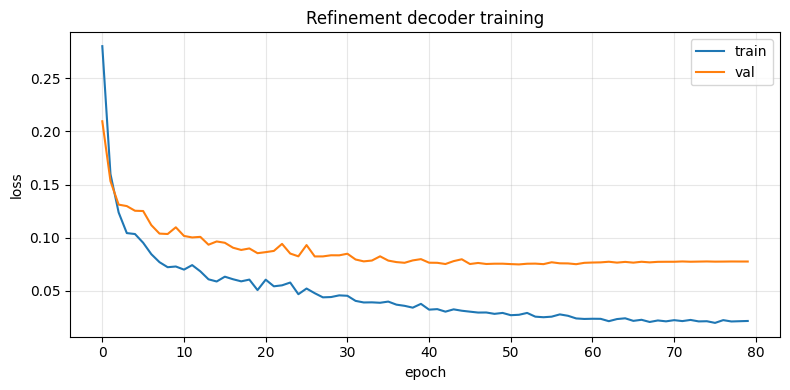

In [ ]:
def dice_loss(pred, target, smooth=1.0):
    p = pred.flatten(1); t = target.flatten(1)
    inter = (p * t).sum(1)
    return 1 - (2 * inter + smooth) / (p.sum(1) + t.sum(1) + smooth)

def focal_bce(pred, target, alpha=0.75, gamma=2.0, eps=1e-6):
    pred = pred.clamp(eps, 1 - eps)
    ce = -(target * torch.log(pred) + (1 - target) * torch.log(1 - pred))
    pt = torch.where(target > 0.5, pred, 1 - pred)
    w  = alpha * (1 - pt).pow(gamma)
    return (w * ce).mean()


EPOCHS = 80
LR     = 1e-3

decoder = RefinementDecoder(feature_dim=FEAT_DIM,
                            image_size=IMAGE_SIZE,
                            hidden=128,
                            heatmap_channels=HM_CH,
                            rgb_channels=3).to(DEVICE)

optimizer = torch.optim.AdamW(decoder.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {"train": [], "val": []}
best_val = float("inf")
SAVE_PATH = "./best_refinement_decoder.pt"

for epoch in range(EPOCHS):

    decoder.train()
    tot = 0.0; n = 0
    for batch in train_refine_ld:
        feats = batch["features"].to(DEVICE)
        hm    = batch["heatmap"].to(DEVICE)
        img   = batch["image"].to(DEVICE)     
        gt    = batch["mask"].to(DEVICE)

        pred = decoder(feats, hm, img)
        loss = 0.5 * focal_bce(pred, gt) + 0.5 * dice_loss(pred, gt).mean()

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(decoder.parameters(), 1.0)
        optimizer.step()
        tot += loss.item() * feats.size(0); n += feats.size(0)
    train_loss = tot / max(1, n)

    decoder.eval()
    tot = 0.0; n = 0
    with torch.no_grad():
        for batch in val_refine_ld:
            feats = batch["features"].to(DEVICE)
            hm    = batch["heatmap"].to(DEVICE)
            img   = batch["image"].to(DEVICE)
            gt    = batch["mask"].to(DEVICE)
            pred  = decoder(feats, hm, img)
            l = 0.5 * focal_bce(pred, gt) + 0.5 * dice_loss(pred, gt).mean()
            tot += l.item() * feats.size(0); n += feats.size(0)
    val_loss = tot / max(1, n)

    history["train"].append(train_loss)
    history["val"].append(val_loss)
    scheduler.step()

    flag = ""
    if val_loss < best_val:
        best_val = val_loss
        torch.save(decoder.state_dict(), SAVE_PATH)
        flag = "  ← saved"
    print(f"epoch {epoch+1:02d}/{EPOCHS}  train={train_loss:.4f}  val={val_loss:.4f}{flag}")

print(f"\n training done. best val loss = {best_val:.4f}  ({SAVE_PATH})")

plt.figure(figsize=(8, 4))
plt.plot(history["train"], label="train")
plt.plot(history["val"],   label="val")
plt.legend(); plt.grid(alpha=0.3); plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Refinement decoder training")
plt.tight_layout(); plt.show()


In [ ]:
decoder.load_state_dict(torch.load(SAVE_PATH, map_location=DEVICE))
decoder.eval()

raw_scores, refined_scores, gt_pixels = [], [], []

with torch.no_grad():
    for batch in tqdm(val_refine_ld, desc="evaluating"):
        feats = batch["features"].to(DEVICE)
        hm    = batch["heatmap"].to(DEVICE)
        img   = batch["image"].to(DEVICE)
        gt    = batch["mask"].to(DEVICE)
        pred  = decoder(feats, hm, img)

        hm_score = hm.max(dim=1, keepdim=True).values   # (B, 1, H, W)

        raw_scores.append(hm_score.cpu().numpy().reshape(-1))
        refined_scores.append(pred.cpu().numpy().reshape(-1))
        gt_pixels.append(gt.cpu().numpy().reshape(-1))

raw      = np.concatenate(raw_scores)
refined  = np.concatenate(refined_scores)
gt_arr   = np.concatenate(gt_pixels).astype(np.uint8)

if np.unique(gt_arr).size >= 2:
    print(f"\n=== Pixel-level metrics on val ({len(gt_arr)} pixels) ===")
    print(f"               MVAD only   MVAD+decoder")
    print(f"  AUROC :       {roc_auc_score(gt_arr, raw):.4f}        {roc_auc_score(gt_arr, refined):.4f}")
    print(f"  AP    :       {average_precision_score(gt_arr, raw):.4f}        {average_precision_score(gt_arr, refined):.4f}")
else:
    print("Only one class in val GT, cannot compute AUROC")


evaluating:   0%|          | 0/87 [00:00<?, ?it/s]


=== Pixel-level metrics on val (34721792 pixels) ===
               MVAD only   MVAD+decoder
  AUROC :       0.8405        0.9983
  AP    :       0.5292        0.9941





In [ ]:
decoder.eval()
n_show = min(40, len(val_refine_ds))
fig, axes = plt.subplots(n_show, 4, figsize=(16, 4 * n_show))
if n_show == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(n_show):
        sample = val_refine_ds[i]
        feats = sample["features"].unsqueeze(0).to(DEVICE)
        hm    = sample["heatmap"].unsqueeze(0).to(DEVICE)
        img_t = sample["image"].unsqueeze(0).to(DEVICE)
        gt    = sample["mask"].squeeze().numpy()
        img   = sample["image"].permute(1, 2, 0).numpy()

        # MVAD-only score: MAX dei due canali della heatmap
        raw = sample["heatmap"].max(dim=0).values.numpy()        # (H, W)
        ref = decoder(feats, hm, img_t).squeeze().cpu().numpy()

        axes[i][0].imshow(img); axes[i][0].set_title(f"input ({sample['class']})"); axes[i][0].axis("off")
        axes[i][1].imshow(raw, cmap="jet"); axes[i][1].set_title("MVAD max-of-channels"); axes[i][1].axis("off")
        axes[i][2].imshow(ref, cmap="jet", vmin=0, vmax=1); axes[i][2].set_title("refined"); axes[i][2].axis("off")
        axes[i][3].imshow(gt, cmap="gray"); axes[i][3].set_title("GT mask"); axes[i][3].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
out_dir = Path("./models_supervised")
out_dir.mkdir(exist_ok=True, parents=True)

torch.save({
    "decoder_state": decoder.state_dict(),
    "feature_dim":   FEAT_DIM,
    "image_size":    IMAGE_SIZE,
    "classes":       CLASSES,
    "history":       history,
}, str(out_dir / "refinement_decoder.pt"))

print(f"Saved to {out_dir / 'refinement_decoder.pt'}")


In [ ]:

def float_matrix_to_q8rle(x: np.ndarray) -> str:
    q = np.clip(np.rint(np.asarray(x, dtype=np.float32) * 255), 0, 255).astype(np.uint8)
    h, w = q.shape
    flat = q.T.reshape(-1)  # column-wise flattening
    if flat.size == 0:
        return f"q8rle {h} {w}"
    cuts = np.flatnonzero(flat[1:] != flat[:-1]) + 1
    starts = np.r_[0, cuts]
    ends = np.r_[cuts, flat.size]
    parts = ["q8rle", str(h), str(w)]
    for v, n in zip(flat[starts], ends - starts):
        parts += [str(int(v)), str(int(n))]
    return " ".join(parts)

def q8rle_to_float_matrix(s: str) -> np.ndarray:
    t = s.split()
    h, w = int(t[1]), int(t[2])
    vals = np.array(list(map(int, t[3::2])), dtype=np.uint8)
    lens = np.array(list(map(int, t[4::2])), dtype=np.int64)
    flat = np.repeat(vals, lens).reshape(w, h).T
    return flat.astype(np.float32) / 255.0


In [ ]:
# Inference
decoder.load_state_dict(torch.load(SAVE_PATH, map_location=DEVICE))
decoder.eval()

SUBMISSION_PATH = "./submission_DINO_LARGE.csv"
rows = []

for cls in CLASSES:
    print(f"\n=== Inference on test: {cls} ===")
    pipe = class_pipelines[cls]

    test_ds = SingleClassDataset(
        ROOT, cls, split="test", image_size=IMAGE_SIZE,
        multi_view=True, require_all_views=False,
    )
    test_ld = DataLoader(test_ds, batch_size=1, shuffle=False,
                         num_workers=0, pin_memory=PIN_MEMORY)

    with torch.no_grad():
        for batch in tqdm(test_ld, desc=cls):
            images_batch = batch["images"]   # (B, 5, C, H, W)
            base_ids     = batch["base_id"]

            for b in range(images_batch.shape[0]):
                base_id = base_ids[b]

                for v in range(images_batch.shape[1]):
                    img_t = images_batch[b, v]  # (C, H, W)

                    feats, hm = mvad_features_and_heatmap(pipe, img_t)
                    img_in    = img_t.unsqueeze(0).to(DEVICE)         # (1, 3, H, W)
                    refined   = decoder(feats.to(DEVICE), hm.to(DEVICE), img_in)
                    refined_np = refined.squeeze().cpu().numpy()

                    rows.append({
                        "ID":    f"{base_id}_view{v + 1}",
                        "Label": float_matrix_to_q8rle(refined_np),
                    })

with open(SUBMISSION_PATH, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["ID", "Label"])
    writer.writeheader()
    writer.writerows(rows)

print(f"\n✓ submission saved → {SUBMISSION_PATH}  ({len(rows)} rows)")



=== Inference on test: class_01 ===


class_01:   0%|          | 0/93 [00:00<?, ?it/s]


=== Inference on test: class_02 ===


class_02:   0%|          | 0/160 [00:00<?, ?it/s]


=== Inference on test: class_03 ===


class_03:   0%|          | 0/158 [00:00<?, ?it/s]

... (7 outputs left out)

class_07:   0%|          | 0/183 [00:00<?, ?it/s]


=== Inference on test: class_08 ===


class_08:   0%|          | 0/192 [00:00<?, ?it/s]


✓ submission saved → ./submission_DINO_LARGE.csv  (5910 rows)





In [ ]:
# ===========================================================
# Visualizzazione: test predictions (no GT mask disponibile)
# ===========================================================
N_SHOW   = 30
CLS_VIS  = "class_08"

pipe_vis = class_pipelines[CLS_VIS]
test_ds_vis = SingleClassDataset(
    ROOT, CLS_VIS, split="test", image_size=IMAGE_SIZE,
    multi_view=True, require_all_views=False,
)

vis_items = []
decoder.eval()

with torch.no_grad():
    for idx in range(min(N_SHOW * 5, len(test_ds_vis))):
        sample = test_ds_vis[idx]
        images = sample["images"]
        base_id = sample["base_id"]

        for v in range(images.shape[0]):
            if len(vis_items) >= N_SHOW:
                break
            img_t = images[v]
            feats, hm = mvad_features_and_heatmap(pipe_vis, img_t)
            img_in    = img_t.unsqueeze(0).to(DEVICE)
            refined = decoder(feats.to(DEVICE), hm.to(DEVICE), img_in).squeeze().cpu().numpy()
            raw_hm  = hm.squeeze().numpy()

            vis_items.append({
                "image":   img_t,
                "raw_hm":  raw_hm,
                "refined": refined,
                "base_id": base_id,
                "view":    v + 1,
            })
        if len(vis_items) >= N_SHOW:
            break

fig, axes = plt.subplots(len(vis_items), 5, figsize=(20, 4 * len(vis_items)))
if len(vis_items) == 1:
    axes = np.expand_dims(axes, axis=0)

col_titles = ["Input image", "PatchCore NN (scaled)", "MVAS recon (scaled)",
              "Refined mask (decoder)", "Overlay refined"]
for ax, t in zip(axes[0], col_titles):
    ax.set_title(t, fontsize=11, fontweight="bold")

for i, item in enumerate(vis_items):
    img_np = tensor_to_numpy_image(item["image"])

    raw_nn   = item["raw_hm"][0]    # NN-distance (scaled — può superare 1)
    raw_mvas = item["raw_hm"][1]    # MVAS recon  (scaled — può superare 1)

    axes[i, 0].imshow(img_np)
    axes[i, 0].set_ylabel(f"{item['base_id']}\nview {item['view']}", fontsize=8)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(raw_nn, cmap="jet"); axes[i, 1].axis("off")
    axes[i, 2].imshow(raw_mvas, cmap="jet"); axes[i, 2].axis("off")
    axes[i, 3].imshow(item["refined"], cmap="jet", vmin=0, vmax=1); axes[i, 3].axis("off")

    overlay = heatmap_overlay(img_np, item["refined"], alpha=0.5)
    axes[i, 4].imshow(overlay); axes[i, 4].axis("off")

plt.suptitle(f"Test predictions — {CLS_VIS}", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


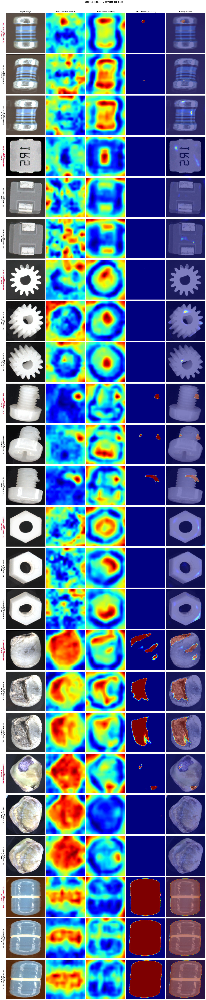

In [ ]:
N_PER_CLASS = 3

vis_items = []
decoder.eval()

with torch.no_grad():
    for cls_name, pipe_vis in class_pipelines.items():
        test_ds_vis = SingleClassDataset(
            ROOT, cls_name, split="test", image_size=IMAGE_SIZE,
            multi_view=True, require_all_views=False,
        )

        collected = 0
        for idx in range(min(N_PER_CLASS * 5, len(test_ds_vis))):
            if collected >= N_PER_CLASS:
                break
            sample = test_ds_vis[idx]
            images = sample["images"]
            base_id = sample["base_id"]

            for v in range(images.shape[0]):
                if collected >= N_PER_CLASS:
                    break
                img_t = images[v]
                feats, hm = mvad_features_and_heatmap(pipe_vis, img_t)
                img_in   = img_t.unsqueeze(0).to(DEVICE)
                refined  = decoder(feats.to(DEVICE), hm.to(DEVICE), img_in).squeeze().cpu().numpy()
                raw_hm   = hm.squeeze().numpy()

                vis_items.append({
                    "class":   cls_name,
                    "image":   img_t,
                    "raw_hm":  raw_hm,
                    "refined": refined,
                    "base_id": base_id,
                    "view":    v + 1,
                })
                collected += 1

fig, axes = plt.subplots(len(vis_items), 5, figsize=(20, 4 * len(vis_items)))
if len(vis_items) == 1:
    axes = np.expand_dims(axes, axis=0)

col_titles = ["Input image", "PatchCore NN (scaled)", "MVAS recon (scaled)",
              "Refined mask (decoder)", "Overlay refined"]
for ax, t in zip(axes[0], col_titles):
    ax.set_title(t, fontsize=11, fontweight="bold")

prev_class = None
for i, item in enumerate(vis_items):
    img_np = tensor_to_numpy_image(item["image"])

    raw_nn   = item["raw_hm"][0]    # NN-distance (scaled)
    raw_mvas = item["raw_hm"][1]    # MVAS recon (scaled)

    is_new_class = item["class"] != prev_class
    label = f"[{item['class']}]\n{item['base_id']}\nview {item['view']}"
    axes[i, 0].imshow(img_np)
    axes[i, 0].set_ylabel(
        label,
        fontsize=9,
        fontweight=("bold" if is_new_class else "normal"),
        color=("crimson" if is_new_class else "black"),
    )
    axes[i, 0].set_xticks([]); axes[i, 0].set_yticks([])
    prev_class = item["class"]

    axes[i, 1].imshow(raw_nn,   cmap="jet"); axes[i, 1].axis("off")
    axes[i, 2].imshow(raw_mvas, cmap="jet"); axes[i, 2].axis("off")
    axes[i, 3].imshow(item["refined"], cmap="jet", vmin=0, vmax=1); axes[i, 3].axis("off")

    overlay = heatmap_overlay(img_np, item["refined"], alpha=0.5)
    axes[i, 4].imshow(overlay); axes[i, 4].axis("off")

plt.suptitle(f"Test predictions — {N_PER_CLASS} samples per class", fontsize=14, y=1.005)
plt.tight_layout()
plt.show()